In [1]:
%config Completer.use_jedi = True
%config IPCompleter.greedy = True

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, GridSearchCV, cross_val_score
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_graphviz, export_text 
from sklearn import tree
from sklearn.metrics import confusion_matrix, accuracy_score
import warnings
warnings.filterwarnings('once')

In [3]:
data = pd.read_csv('manufacturing_risk_assessment.csv')
data.head()

,risk_level,motor_temperature,motor_vibration_level,motor_load_percentage,motor_speed_rpm,motor_current_amp,motor_voltage_v,motor_efficiency_index,motor_wear_index,motor_noise_level,...,system_recovery_capacity,system_adaptability,system_flexibility,system_redundancy,system_backup_integrity,system_overload_tolerance,system_failure_tolerance,system_operational_margin,system_safety_index,system_overall_health
0,Moderate,0.0,2.497,0,0,18,5,13,0,0,...,0,0,0,0,0,1,1,1,1,0
1,Negligible,0.0,0.153,0,0,15,4,11,0,0,...,0,0,0,0,1,0,0,0,0,0
2,Negligible,0.0,-2.046,0,0,12,6,6,0,0,...,0,0,0,0,0,0,0,0,0,0
3,Critical,0.0,3.657,0,0,25,4,21,0,0,...,0,0,0,0,0,2,0,0,0,0
4,Moderate,0.0,2.332,0,0,28,7,21,0,0,...,0,0,0,0,1,0,0,0,0,0


In [4]:
data.describe()

,motor_temperature,motor_vibration_level,motor_load_percentage,motor_speed_rpm,motor_current_amp,motor_voltage_v,motor_efficiency_index,motor_wear_index,motor_noise_level,motor_alignment_score,...,system_recovery_capacity,system_adaptability,system_flexibility,system_redundancy,system_backup_integrity,system_overload_tolerance,system_failure_tolerance,system_operational_margin,system_safety_index,system_overall_health
count,281.000000,281.000000,281.000000,281.000000,281.00000,281.000000,281.000000,281.000000,281.0,281.0,...,281.000000,281.000000,281.000000,281.000000,281.000000,281.000000,281.000000,281.000000,281.000000,281.000000
mean,69.758409,1.954922,0.081851,0.060498,24.16726,6.188612,17.950178,0.017794,0.0,0.0,...,0.014235,0.017794,0.024911,0.003559,0.384342,0.274021,0.042705,0.021352,0.366548,0.181495
std,617.133622,2.880014,0.322476,0.253346,12.51130,4.305729,9.519398,0.157106,0.0,0.0,...,0.118669,0.132436,0.177539,0.059655,1.056428,0.769741,0.219476,0.144814,1.200068,0.897902
min,0.000000,-7.055000,0.000000,0.000000,5.00000,0.000000,0.000000,0.000000,0.0,0.0,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,0.005500,0.082000,0.000000,0.000000,16.00000,4.000000,11.000000,0.000000,0.0,0.0,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,0.430000,2.051000,0.000000,0.000000,22.00000,5.000000,18.000000,0.000000,0.0,0.0,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
75%,5.420000,3.834000,0.000000,0.000000,29.00000,8.000000,22.000000,0.000000,0.0,0.0,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
max,9600.000000,14.360000,3.000000,2.000000,100.00000,33.000000,67.000000,2.000000,0.0,0.0,...,1.000000,1.000000,2.000000,1.000000,13.000000,9.000000,2.000000,1.000000,12.000000,11.000000


In [5]:
print(data.isna().sum())

risk_level                   0
motor_temperature            0
motor_vibration_level        0
motor_load_percentage        0
motor_speed_rpm              0
                            ..
system_overload_tolerance    0
system_failure_tolerance     0
system_operational_margin    0
system_safety_index          0
system_overall_health        0
Length: 193, dtype: int64


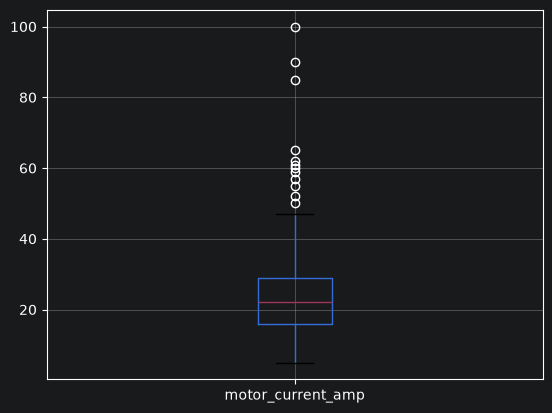

In [6]:
data.boxplot(column='motor_current_amp')
plt.show()

In [7]:
Q1 = data['motor_current_amp'].quantile(0.25)
Q3 = data['motor_current_amp'].quantile(0.75)
IQR = Q3-Q1
lower_bound = Q1 -1.5 * IQR
upper_bound = Q3 + 1.5 * IQR
outliers = data[(data['motor_current_amp'] < lower_bound) | (data['motor_current_amp'] > upper_bound)]
num_outliers = outliers.shape[0]
print(f'Número de outliers en motor_current_amp: {num_outliers}')

Número de outliers en motor_current_amp: 12


In [8]:
from scipy.stats import zscore

# 1. Calculamos el Z-Score absoluto para la variable seleccionada
# (np.abs convierte los valores negativos en positivos para evaluar ambos extremos a la vez)
z = np.abs(zscore(data['motor_current_amp']))

# 2. Filtramos el DataFrame original buscando los registros donde el Z-Score supere el umbral
# IMPORTANTE: En Python los decimales se ponen siempre con PUNTO (1.5), no con coma
outliers_z = data[z > 2]

# 3. Contamos cuántos registros cumplen la condición y lo mostramos en pantalla
num_outliers_z = len(outliers_z)
print(f'Número de outliers en motor_current_amp (usando Z-Score): {num_outliers_z}')

Número de outliers en motor_current_amp (usando Z-Score): 12


In [9]:
num_nulos=data['robotic_arm_cycle_time'].isnull().sum()
print(f'Número de valores nulos en robotic_arm_cycle_time: {num_nulos}')

Número de valores nulos en robotic_arm_cycle_time: 0


In [10]:
X=data.drop('risk_level',axis=1)
y=data['risk_level']
X_train,X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=1)
num_estancias_train = X_train.shape[0]
print(f'Número de instancias en el conjunto de entrenamiento: {num_estancias_train}')

Número de instancias en el conjunto de entrenamiento: 196


In [11]:
from sklearn.metrics import classification_report
model = DecisionTreeClassifier(random_state=1)
model.fit(X_train, y_train)
y_tree_pred = model.predict(X_test) #Predicciones del árbol de decisión sin podar. 

#Matriz de confusión
cm = confusion_matrix(y_test, y_tree_pred)
print("Matriz de confusión:")
print(cm)
print("Informe de clasificación:\n", (classification_report(y_test, y_tree_pred)))
print("La precisión de la clase Negligible es 0.44")

Matriz de confusión:
[[ 1  9  2]
 [ 4 17 20]
 [ 1 14 17]]
Informe de clasificación:
               precision    recall  f1-score   support

    Critical       0.17      0.08      0.11        12
    Moderate       0.42      0.41      0.42        41
  Negligible       0.44      0.53      0.48        32

    accuracy                           0.41        85
   macro avg       0.34      0.34      0.34        85
weighted avg       0.39      0.41      0.40        85

La precisión de la clase Negligible es 0.44


In [12]:
from sklearn.dummy import DummyClassifier
dummy_clf=DummyClassifier(strategy='most_frequent', random_state=1) #Llamada al clasificador trivial
dummy_clf.fit(X_train, y_train)
y_dummy_pred=dummy_clf.predict(X_test) #Predicciones del clasificador trivial
print("Informe de clasificación del clasificador trivial:\n", classification_report(y_test, y_dummy_pred, zero_division=0))

# Otra manera más fácil:
print("La clase que siempre predice el clasificador trivial es la más frecuente, que es: ", y_train.value_counts().idxmax())

Informe de clasificación del clasificador trivial:
               precision    recall  f1-score   support

    Critical       0.00      0.00      0.00        12
    Moderate       0.48      1.00      0.65        41
  Negligible       0.00      0.00      0.00        32

    accuracy                           0.48        85
   macro avg       0.16      0.33      0.22        85
weighted avg       0.23      0.48      0.31        85

La clase que siempre predice el clasificador trivial es la más frecuente, que es:  Moderate


In [13]:
accuracy=accuracy_score(y_test, y_dummy_pred)
print(f'El Accuracy del clasificador trivial es: {accuracy:.4f}')

El Accuracy del clasificador trivial es: 0.4824


In [14]:
param_grid={'max_depth':range(1,21)}
grid=GridSearchCV(estimator=DecisionTreeClassifier(random_state=1), param_grid=param_grid, cv=5, scoring='accuracy')
grid.fit(X_train, y_train)
best_tree=grid.best_estimator_
y_best_tree_pred= best_tree.predict(X_test)
print(classification_report(y_test, y_best_tree_pred, labels=best_tree.classes_))
reporte = classification_report(y_test, y_best_tree_pred, output_dict=True)
precision_negligible = reporte['Negligible']['precision']
print(f'La precisión de la clase Negligible es: {precision_negligible:.4f}')

              precision    recall  f1-score   support

    Critical       0.17      0.08      0.11        12
    Moderate       0.56      0.78      0.65        41
  Negligible       0.73      0.50      0.59        32

    accuracy                           0.58        85
   macro avg       0.49      0.45      0.45        85
weighted avg       0.57      0.58      0.55        85

La precisión de la clase Negligible es: 0.7273


In [15]:
recall_critical=reporte['Critical']['recall']
print(f"El recall de la clase Critical es {recall_critical:.4f}")

El recall de la clase Critical es 0.0833


In [16]:
f1score_moderate=reporte['Moderate']['f1-score']
print(f"El F1-score de la clase Moderate es {f1score_moderate:.4f}")

El F1-score de la clase Moderate es 0.6531


In [17]:
importances=best_tree.feature_importances_
feature_importance=pd.Series(importances,index=X_train.columns).sort_values(ascending=False)
print(f'Importancia de cooling_system_temperature: {feature_importance["cooling_system_temperature"]:.3f}')

Importancia de cooling_system_temperature: 0.000


In [18]:
print(f'Importancia de sensor_accuracy_score: {feature_importance["sensor_accuracy_score"]:.3f}')

Importancia de sensor_accuracy_score: 0.061


### Parte 2. Desarrollo

In [19]:
datos_parte2_original=pd.read_csv('predicciones_modelos_c.csv')
datos_parte2_original.head()

,Unnamed: 0,Model 1,Model 2,Model 3,Clase real
0,1,Moderate,Moderate,Critical,Moderate
1,2,Moderate,Negligible,Critical,Negligible
2,3,Negligible,Negligible,Critical,Negligible
3,4,Critical,Critical,Critical,Critical
4,5,Negligible,Negligible,Critical,Moderate


In [20]:
datos_parte2_original.describe()

,Unnamed: 0
count,19.000000
mean,10.000000
std,5.627314
min,1.000000
25%,5.500000
50%,10.000000
75%,14.500000
max,19.000000


In [21]:
print(datos_parte2_original.isna().sum())

Unnamed: 0    0
Model 1       0
Model 2       0
Model 3       0
Clase real    0
dtype: int64


In [22]:
datos_parte2 = datos_parte2_original.drop(columns=['Unnamed: 0'])

In [23]:
print(datos_parte2.isna().sum())

Model 1       0
Model 2       0
Model 3       0
Clase real    0
dtype: int64


In [24]:
datos_parte2.describe()

,Model 1,Model 2,Model 3,Clase real
count,19,19,19,19
unique,3,3,1,3
top,Moderate,Negligible,Critical,Negligible
freq,9,11,19,12


In [25]:
print(datos_parte2.isna().sum())

Model 1       0
Model 2       0
Model 3       0
Clase real    0
dtype: int64


In [26]:
datos_parte2.head(20)

,Model 1,Model 2,Model 3,Clase real
0,Moderate,Moderate,Critical,Moderate
1,Moderate,Negligible,Critical,Negligible
2,Negligible,Negligible,Critical,Negligible
3,Critical,Critical,Critical,Critical
4,Negligible,Negligible,Critical,Moderate
5,Negligible,Negligible,Critical,Negligible
6,Negligible,Critical,Critical,Negligible
7,Moderate,Negligible,Critical,Negligible
8,Moderate,Negligible,Critical,Negligible
9,Negligible,Moderate,Critical,Negligible


In [27]:
# Matrices de confusión de cada modelo

y_test=datos_parte2['Clase real']

# Definir clases
clases = sorted(y_test.unique())

# Matrices de confusión
y_model_1 = datos_parte2['Model 1']
y_model_2 = datos_parte2['Model 2']
y_model_3 = datos_parte2['Model 3']

cm_model_1 = confusion_matrix(y_test, y_model_1)
cm_model_2 = confusion_matrix(y_test, y_model_2)
cm_model_3 = confusion_matrix(y_test, y_model_3)

# Convertir a DataFrame
df_cm1 = pd.DataFrame(cm_model_1, index=clases, columns=clases)
df_cm2 = pd.DataFrame(cm_model_2, index=clases, columns=clases)
df_cm3 = pd.DataFrame(cm_model_3, index=clases, columns=clases)

# Mostrar
print("Filas = valores reales | Columnas = predicciones\n")

print("=== Matriz de confusión del Modelo 1 ===\n")
print(df_cm1)

print("\n=== Matriz de confusión del Modelo 2 ===\n")
print(df_cm2)

print("\n=== Matriz de confusión del Modelo 3 ===\n")
print(df_cm3)

Filas = valores reales | Columnas = predicciones

=== Matriz de confusión del Modelo 1 ===

            Critical  Moderate  Negligible
Critical           1         0           0
Moderate           0         4           2
Negligible         0         5           7

=== Matriz de confusión del Modelo 2 ===

            Critical  Moderate  Negligible
Critical           1         0           0
Moderate           0         4           2
Negligible         1         2           9

=== Matriz de confusión del Modelo 3 ===

            Critical  Moderate  Negligible
Critical           1         0           0
Moderate           6         0           0
Negligible        12         0           0


In [28]:
print("=== Reporte de clasificación - Modelo 1 ===\n")
print(classification_report(y_test, y_model_1, zero_division=0))

print("\n=== Reporte de clasificación - Modelo 2 ===\n")
print(classification_report(y_test, y_model_2, zero_division=0))

print("\n=== Reporte de clasificación - Modelo 3 (Trivial) ===\n")
print(classification_report(y_test, y_model_3, zero_division=0))

=== Reporte de clasificación - Modelo 1 ===

              precision    recall  f1-score   support

    Critical       1.00      1.00      1.00         1
    Moderate       0.44      0.67      0.53         6
  Negligible       0.78      0.58      0.67        12

    accuracy                           0.63        19
   macro avg       0.74      0.75      0.73        19
weighted avg       0.68      0.63      0.64        19


=== Reporte de clasificación - Modelo 2 ===

              precision    recall  f1-score   support

    Critical       0.50      1.00      0.67         1
    Moderate       0.67      0.67      0.67         6
  Negligible       0.82      0.75      0.78        12

    accuracy                           0.74        19
   macro avg       0.66      0.81      0.71        19
weighted avg       0.75      0.74      0.74        19


=== Reporte de clasificación - Modelo 3 (Trivial) ===

              precision    recall  f1-score   support

    Critical       0.05      1.00   

In [29]:
# Accuracy = Aciertos / total
# Error Rate = 1 - accuracy

# Modelo 1
acc1 = accuracy_score(y_test, y_model_1) 
err1 = 1 - acc1 

# Modelo 2
acc2 = accuracy_score(y_test, y_model_2)
err2 = 1 - acc2

# Modelo 3
acc3 = accuracy_score(y_test, y_model_3)
err3 = 1 - acc3

# Mostrar resultados
print(f"Modelo 1 -> Accuracy: {acc1:.4f} | Error Rate: {err1:.4f}")
print(f"Modelo 2 -> Accuracy: {acc2:.4f} | Error Rate: {err2:.4f}")
print(f"Modelo 3 -> Accuracy: {acc3:.4f} | Error Rate: {err3:.4f}")

Modelo 1 -> Accuracy: 0.6316 | Error Rate: 0.3684
Modelo 2 -> Accuracy: 0.7368 | Error Rate: 0.2632
Modelo 3 -> Accuracy: 0.0526 | Error Rate: 0.9474


In [30]:
# Agrupo las predicciones y definir las clases objetivo
predicciones_modelos = {'Modelo 1': y_model_1, 'Modelo 2': y_model_2, 'Modelo 3': y_model_3}
clases_objetivo = ['Negligible', 'Moderate', 'Critical']

# Recorro cada modelo y cada clase para imprimir el texto exacto
for nombre_modelo, y_prediccion in predicciones_modelos.items():
    print(f"\n--- Métricas individuales para el {nombre_modelo} ---")
    
    # Genero el reporte como diccionario para poder extraer datos
    reporte_dict = classification_report(y_test, y_prediccion, zero_division=0, output_dict=True)
    
    for clase in clases_objetivo:
        if clase in reporte_dict:
            val_precision = reporte_dict[clase]['precision']
            val_recall = reporte_dict[clase]['recall']
            val_f1 = reporte_dict[clase]['f1-score']
            
            print(f"Clase {clase} -> Precision: {val_precision:.4f} | Recall: {val_recall:.4f} | F1-score: {val_f1:.4f}")


--- Métricas individuales para el Modelo 1 ---
Clase Negligible -> Precision: 0.7778 | Recall: 0.5833 | F1-score: 0.6667
Clase Moderate -> Precision: 0.4444 | Recall: 0.6667 | F1-score: 0.5333
Clase Critical -> Precision: 1.0000 | Recall: 1.0000 | F1-score: 1.0000

--- Métricas individuales para el Modelo 2 ---
Clase Negligible -> Precision: 0.8182 | Recall: 0.7500 | F1-score: 0.7826
Clase Moderate -> Precision: 0.6667 | Recall: 0.6667 | F1-score: 0.6667
Clase Critical -> Precision: 0.5000 | Recall: 1.0000 | F1-score: 0.6667

--- Métricas individuales para el Modelo 3 ---
Clase Negligible -> Precision: 0.0000 | Recall: 0.0000 | F1-score: 0.0000
Clase Moderate -> Precision: 0.0000 | Recall: 0.0000 | F1-score: 0.0000
Clase Critical -> Precision: 0.0526 | Recall: 1.0000 | F1-score: 0.1000


In [31]:
def calcular_roc(y_true, y_pred):
    # Convertir a binario
    y_true_bin = y_true.apply(lambda x: 1 if x in ['Moderate', 'Critical'] else 0)
    y_pred_bin = y_pred.apply(lambda x: 1 if x in ['Moderate', 'Critical'] else 0)
    
    # Matriz de confusión binaria
    tn, fp, fn, tp = confusion_matrix(y_true_bin, y_pred_bin).ravel()
    
    # Cálculo métricas
    tpr = tp / (tp + fn)
    fpr = fp / (fp + tn)
    
    return tpr, fpr

# Aplicar a cada modelo
tpr1, fpr1 = calcular_roc(y_test, y_model_1)
tpr2, fpr2 = calcular_roc(y_test, y_model_2)
tpr3, fpr3 = calcular_roc(y_test, y_model_3)

# Mostrar resultados
print(f"Modelo 1 -> TPR: {tpr1:.4f}, FPR: {fpr1:.4f}")
print(f"Modelo 2 -> TPR: {tpr2:.4f}, FPR: {fpr2:.4f}")
print(f"Modelo 3 -> TPR: {tpr3:.4f}, FPR: {fpr3:.4f}")

Modelo 1 -> TPR: 0.7143, FPR: 0.4167
Modelo 2 -> TPR: 0.7143, FPR: 0.2500
Modelo 3 -> TPR: 1.0000, FPR: 1.0000
